## Read in Data

In [86]:
# Import necessary packages
import pandas as pd
import re
from os.path import join
import numpy as np
import string

In [ ]:
# Define test sets
testsets = ['twitter-test1.txt', 'twitter-test2.txt', 'twitter-test3.txt']
# devset = ["twitter-dev-data.txt"]

test_eval = True

In [88]:
train = pd.read_csv("twitter-training-data.txt", names=["tweet_id", "sentiment", "text"],delimiter="\t")
val = pd.read_csv("twitter-dev-data.txt", names=["tweet_id", "sentiment", "text"],delimiter="\t")

test_1 = pd.read_csv("twitter-test1.txt", names=["tweet_id", "sentiment", "text"],delimiter="\t")
test_2 = pd.read_csv("twitter-test2.txt", names=["tweet_id", "sentiment", "text"],delimiter="\t")
test_3 = pd.read_csv("twitter-test3.txt", names=["tweet_id", "sentiment", "text"],delimiter="\t")

df_objects = [train, val, test_1, test_2, test_3]

train.head()

,tweet_id,sentiment,text
0,335104872099066692,positive,Felt privileged to play Foo Fighters songs on ...
1,796528524030124618,positive,@AaqibAfzaal Pakistan may be an Islamic countr...
2,760964834217238632,positive,Happy Birthday to the coolest golfer in Bali! ...
3,147713180324524046,negative,@SimpplyA TMILLS is going to Tucson! But the 2...
4,732302280474120023,negative,Hmmmmm where are the #BlackLivesMatter when ma...


In [89]:
# for i in range(train.shape[0]):
#     print(i, train["text"].iloc[i])

In [90]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.data.path = ['C:/Users/Dhyey/anaconda3/nltk_data']  # or any clean, writable path

nltk.download('all', download_dir='C:/Users/Dhyey/anaconda3/nltk_data')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to
[nltk_data]    |     C:/Users/Dhyey/anaconda3/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to
[nltk_data]    |     C:/Users/Dhyey/anaconda3/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     C:/Users/Dhyey/anaconda3/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     C:/Users/Dhyey/anaconda3/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     C:/Users/Dhyey/anaconda3/nltk_data...
[nltk_data]    |   Package aver

True

In [91]:
# !pip install contractions
# !pip install emoji

import re
import string
import nltk
import contractions
import emoji
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

# Initialize resources
lemmatizer = WordNetLemmatizer()
# lemmatizer = PorterStemmer()

# Build stop words list but keep negation words
stop_words = set(stopwords.words('english'))
stop_words.difference_update({'no', 'not', 'nor'})

def clean_text(text):
    try:
        # Convert text to lowercase
        text = text.lower()
        
        # Expand contractions (e.g., "can't" -> "cannot")
        text = contractions.fix(text)
        
        # Remove URLs
        text = re.sub(r'http\S+', '', text)

        # Remove mentions (e.g., @username)
        text = re.sub(r'@\w+', '', text)
        
        # Remove the hashtag symbol but keep the word (or you could choose to keep it)
        text = re.sub(r'#', '', text)
        
        # Convert emojis to descriptive text (e.g., "😊" -> ":smiling_face_with_smiling_eyes:")
        text = emoji.demojize(text)
        
        # Remove punctuation
        text = text.translate(str.maketrans('', '', string.punctuation))
        
        # Normalize elongated words (e.g., "soooo" -> "soo")
        text = re.sub(r'(.)\1{2,}', r'\1', text)
        
        # Remove extra whitespace
        text = re.sub(r'\s+', ' ', text).strip()

        # Tokenize the text into words
        tokens = text.split()
        
        # Remove stop words (keeping negation words since they're removed from stop_words above)
        tokens = [word for word in tokens if word not in stop_words]
        
        # Lemmatize or stem tokens
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

        # print("Re-joining")
        # Re-join tokens into a cleaned string
        cleaned_text = " ".join(tokens)

        return cleaned_text

    except:
        print(text)
        return text

from scipy.sparse import csr_matrix, hstack

def pos_counts(text):
    """
    Tokenizes the cleaned tweet text (assuming words are separated by whitespace)
    and returns a list of counts for adjectives, nouns, verbs, and adverbs.
    """
    tokens = text.split()  # simple tokenization based on whitespace
    tags = nltk.pos_tag(tokens)
    adjectives = sum(1 for word, tag in tags if tag.startswith('JJ'))
    nouns      = sum(1 for word, tag in tags if tag.startswith('NN'))
    verbs      = sum(1 for word, tag in tags if tag.startswith('VB'))
    adverbs    = sum(1 for word, tag in tags if tag.startswith('RB'))
    return [adjectives, nouns, verbs, adverbs]

In [92]:
for df in df_objects:
    df["text"] = df["text"].apply(lambda x: clean_text(x))

val.sample(frac=1.0).head()

,tweet_id,sentiment,text
1484,393109313062204211,neutral,gif niall hitting harry ball last night bent q...
600,300847449776544359,neutral,obama get high horse christian cmon mr preside...
22,545033260723245760,neutral,david beckham may ask check profile limited se...
1905,358144902062206401,positive,thanks jesus cv mom maryi able kick flu 1 week...
641,623910592184772154,neutral,front line kamran shahid latest 25 june 2012


In [93]:
import nltk
nltk.download('opinion_lexicon')
from nltk.corpus import opinion_lexicon
positive_words = set(opinion_lexicon.positive())
negative_words = set(opinion_lexicon.negative())

[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     c:\Users\Dhyey\anaconda3\nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


In [94]:
# # Define lexicon_features function to count positive and negative words
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from scipy.sparse import csr_matrix, hstack
from collections import Counter
import numpy as np

def lexicon_features(text):
    tokens = text.split()
    pos_count = sum(1 for token in tokens if token in positive_words)
    neg_count = sum(1 for token in tokens if token in negative_words)
    return [pos_count, neg_count]

### Pick feature embedding variation

Variation 1: TF-IDF + POS Counts

In [95]:
# # Compute POS features (each feature vector is [#adjectives, #nouns, #verbs, #adverbs])
# train_pos_features = [pos_counts(text) for text in train["text"]]
# val_pos_features   = [pos_counts(text) for text in val["text"]]

# # Convert the lists to numpy arrays and then to sparse matrices
# train_pos_sparse = csr_matrix(np.array(train_pos_features))
# val_pos_sparse   = csr_matrix(np.array(val_pos_features))

# tfidf = TfidfVectorizer()

# # Tfidf features on cleaned text
# X_train_tfidf = tfidf.fit_transform(train["text"])
# X_val_tfidf   = tfidf.transform(val["text"])

# # Combine (horizontally stack) the Tfidf features and the POS count features
# X_train = hstack([X_train_tfidf, train_pos_sparse])
# X_val = hstack([X_val_tfidf, val_pos_sparse])

# print("Combined feature matrix shape (train):", X_train.shape)

# y_train = train["sentiment"]
# y_val = val["sentiment"]
# print(y_train.value_counts())

Variation 2: CountVectorizer (Raw Counts) + Sentiment Lexicon Features


In [96]:
from sklearn.feature_extraction.text import CountVectorizer
from scipy.sparse import hstack, csr_matrix
import numpy as np
from collections import Counter

# --- Train & Validation ---

# Compute lexicon features
train_lex_features = [lexicon_features(text) for text in train["text"]]
val_lex_features   = [lexicon_features(text) for text in val["text"]]

# Convert to sparse matrices
train_lex_sparse = csr_matrix(np.array(train_lex_features))
val_lex_sparse   = csr_matrix(np.array(val_lex_features))

# CountVectorizer on unigrams and bigrams
count_vect = CountVectorizer(ngram_range=(1, 2))
X_train_counts = count_vect.fit_transform(train["text"])
X_val_counts   = count_vect.transform(val["text"])

# Combine count and lexicon features
X_train = hstack([X_train_counts, train_lex_sparse])
X_val   = hstack([X_val_counts, val_lex_sparse])

y_train = train["sentiment"]
y_val   = val["sentiment"]

print("Variation 2: CountVectorizer + Sentiment Lexicon Features")
print("Combined feature matrix shape (train):", X_train.shape)
print("Training class distribution:", Counter(y_train))

# --- Test Sets ---

# Compute lexicon features
test_1_lex = csr_matrix(np.array([lexicon_features(t) for t in test_1["text"]]))
test_2_lex = csr_matrix(np.array([lexicon_features(t) for t in test_2["text"]]))
test_3_lex = csr_matrix(np.array([lexicon_features(t) for t in test_3["text"]]))

# Vectorize using the trained CountVectorizer
X_test_1_counts = count_vect.transform(test_1["text"])
X_test_2_counts = count_vect.transform(test_2["text"])
X_test_3_counts = count_vect.transform(test_3["text"])

# Combine with lexicon features
X_test_1 = hstack([X_test_1_counts, test_1_lex])
X_test_2 = hstack([X_test_2_counts, test_2_lex])
X_test_3 = hstack([X_test_3_counts, test_3_lex])

y_test_1 = test_1["sentiment"]
y_test_2 = test_2["sentiment"]
y_test_3 = test_3["sentiment"]

# print("Test 1 shape:", X_test_1.shape, "| Distribution:", Counter(y_test_1))
# print("Test 2 shape:", X_test_2.shape, "| Distribution:", Counter(y_test_2))
# print("Test 3 shape:", X_test_3.shape, "| Distribution:", Counter(y_test_3))

Variation 2: CountVectorizer + Sentiment Lexicon Features
Combined feature matrix shape (train): (45026, 352835)
Training class distribution: Counter({'neutral': 20749, 'positive': 15960, 'negative': 8317})


Variation 3: TF-IDF + Sentiment Lexicon Features


In [97]:
# # # Compute lexicon features for train and validation texts
# train_lex_features = [lexicon_features(text) for text in train["text"]]
# val_lex_features   = [lexicon_features(text) for text in val["text"]]

# # Convert lexicon feature lists to sparse matrices
# train_lex_sparse = csr_matrix(np.array(train_lex_features))
# val_lex_sparse   = csr_matrix(np.array(val_lex_features))

# # Create TF-IDF features on cleaned text
# tfidf = TfidfVectorizer()
# X_train_tfidf = tfidf.fit_transform(train["text"])
# X_val_tfidf   = tfidf.transform(val["text"])

# # Combine TF-IDF features with lexicon features
# X_train = hstack([X_train_tfidf, train_lex_sparse])
# X_val   = hstack([X_val_tfidf, val_lex_sparse])

# y_train = train["sentiment"]
# y_val   = val["sentiment"]

# print("Variation 3: TF-IDF + Sentiment Lexicon Features")
# print("Combined feature matrix shape (train):", X_train.shape)
# print("Training class distribution:", Counter(y_train))

# # --- Compute Lexicon Features for Each Test Set ---
# test_1_lex_features = [lexicon_features(text) for text in test_1["text"]]
# test_2_lex_features = [lexicon_features(text) for text in test_2["text"]]
# test_3_lex_features = [lexicon_features(text) for text in test_3["text"]]

# # --- Convert Lexicon Features to Sparse Matrices ---
# test_1_lex_sparse = csr_matrix(np.array(test_1_lex_features))
# test_2_lex_sparse = csr_matrix(np.array(test_2_lex_features))
# test_3_lex_sparse = csr_matrix(np.array(test_3_lex_features))

# # --- Create TF-IDF Features for Each Test Set Using Trained Vectorizer ---
# X_test_1_tfidf = tfidf.transform(test_1["text"])
# X_test_2_tfidf = tfidf.transform(test_2["text"])
# X_test_3_tfidf = tfidf.transform(test_3["text"])

# # --- Combine TF-IDF and Lexicon Features ---
# X_test_1 = hstack([X_test_1_tfidf, test_1_lex_sparse])
# X_test_2 = hstack([X_test_2_tfidf, test_2_lex_sparse])
# X_test_3 = hstack([X_test_3_tfidf, test_3_lex_sparse])

# # --- Extract Sentiment Labels ---
# y_test_1 = test_1["sentiment"]
# y_test_2 = test_2["sentiment"]
# y_test_3 = test_3["sentiment"]

# # Optional: Display shapes and class distributions
# print("Test 1 shape:", X_test_1.shape, "| Distribution:", Counter(y_test_1))
# print("Test 2 shape:", X_test_2.shape, "| Distribution:", Counter(y_test_2))
# print("Test 3 shape:", X_test_3.shape, "| Distribution:", Counter(y_test_3))


### Helper functions

In [98]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, recall_score

# Helper to compute macro-F1 for positive & negative classes only
def macro_f1_pos_neg(y_true, y_pred):
    f1_pos = f1_score(y_true, y_pred, labels=['positive'], average='macro', zero_division=0)
    f1_neg = f1_score(y_true, y_pred, labels=['negative'], average='macro', zero_division=0)
    return (f1_pos + f1_neg) / 2

# Helper to print accuracy and F1 scores
def print_metrics(y_true, y_pred, dataset_name=""):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')  # all three classes
    macro_f1_posneg = macro_f1_pos_neg(y_true, y_pred)
    avg_rec = recall_score(y_true, y_pred, average='macro')
    
    if dataset_name:
        print(f"Evaluation on {dataset_name}:")
    print(f"  Accuracy = {acc:.4f}")
    print(f"  Macro-F1 (all 3 classes) = {macro_f1:.4f}")
    print(f"  Macro-F1 (Positive & Negative only) = {macro_f1_posneg:.4f}")
    print(f"  AvgRec = {avg_rec:.4f}")


# Helper to display confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion_matrix(y_true, y_pred, classes=['positive','negative','neutral'], title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

def evaluate_model(model, X_test, y_test, dataset_name, title):
    """
    Evaluates a given model on the test set.
    - model: the trained model (with a .predict() method)
    - X_test: feature matrix for the test set
    - y_test: true labels for the test set
    - dataset_name: string label for printing (e.g., "Test Set 1")
    - title: title for the confusion matrix plot
    """
    y_pred = model.predict(X_test)
    print(f"\nEvaluation for {dataset_name}:")
    print_metrics(y_test, y_pred, dataset_name=dataset_name)
    plot_confusion_matrix(y_test, y_pred, title=title)

## Standard Model Building

In [99]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

### MaxEnt

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Logistic Regression C: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best cross-val F1 (macro): 0.6420744386239213
Evaluation on Dev (LogReg):
  Accuracy = 0.6800
  Macro-F1 (all 3 classes) = 0.6747
  Macro-F1 (Positive & Negative only) = 0.6708
  AvgRec = 0.6828


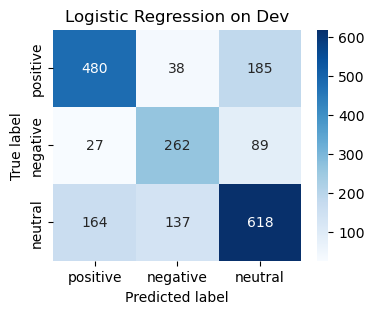

In [100]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')  # liblinear is good for small multiclass

param_grid_lr = [
    {
        'penalty': ['l2'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'solver': ['lbfgs', 'liblinear'],  # lbfgs is efficient; liblinear works with smaller datasets and l1 as well
    },
    {
        'penalty': ['l1'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'solver': ['liblinear'],  # liblinear supports l1
    }
]

grid_lr = GridSearchCV(log_reg, param_grid_lr, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Best Logistic Regression C:", grid_lr.best_params_)
print("Best cross-val F1 (macro):", grid_lr.best_score_)

best_lr = grid_lr.best_estimator_
y_dev_pred_lr = best_lr.predict(X_val)
print_metrics(y_val, y_dev_pred_lr, dataset_name="Dev (LogReg)")
plot_confusion_matrix(y_val, y_dev_pred_lr, title="Logistic Regression on Dev")


Evaluation for Test Set 1:
Evaluation on Test Set 1:
  Accuracy = 0.6865
  Macro-F1 (all 3 classes) = 0.6660
  Macro-F1 (Positive & Negative only) = 0.6505
  AvgRec = 0.6531


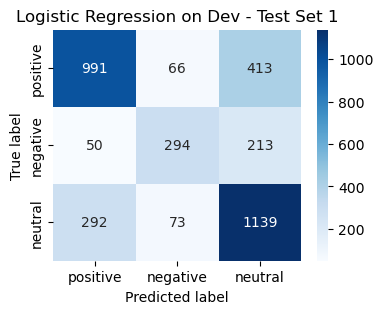


Evaluation for Test Set 2:
Evaluation on Test Set 2:
  Accuracy = 0.6724
  Macro-F1 (all 3 classes) = 0.6482
  Macro-F1 (Positive & Negative only) = 0.6631
  AvgRec = 0.6407


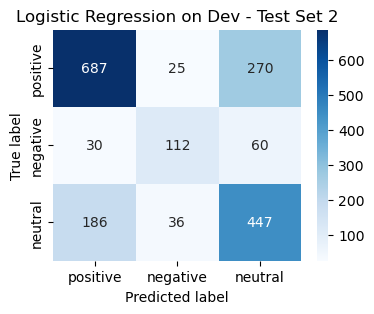


Evaluation for Test Set 3:
Evaluation on Test Set 3:
  Accuracy = 0.6435
  Macro-F1 (all 3 classes) = 0.6202
  Macro-F1 (Positive & Negative only) = 0.6004
  AvgRec = 0.6203


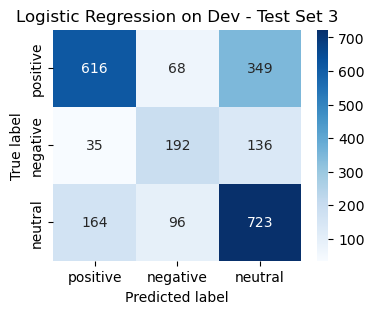

In [101]:
if test_eval:
    evaluate_model(best_lr, X_test_1, y_test_1, dataset_name="Test Set 1", title="Logistic Regression on Dev - Test Set 1")
    evaluate_model(best_lr, X_test_2, y_test_2, dataset_name="Test Set 2", title="Logistic Regression on Dev - Test Set 2")
    evaluate_model(best_lr, X_test_3, y_test_3, dataset_name="Test Set 3", title="Logistic Regression on Dev - Test Set 3")

### Multinomial Naive Bayes

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best NB parameters: {'alpha': 0.5, 'fit_prior': True}
Best cross-val F1 (macro): 0.5963412789161041
Evaluation on Val (Multinomial NB):
  Accuracy = 0.6345
  Macro-F1 (all 3 classes) = 0.6192
  Macro-F1 (Positive & Negative only) = 0.6058
  AvgRec = 0.6070


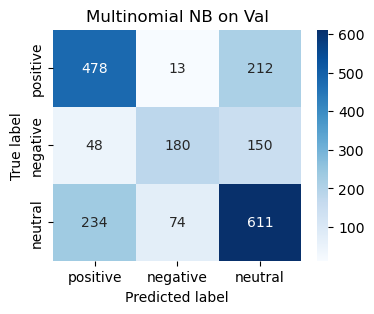

In [102]:
from sklearn.naive_bayes import MultinomialNB
nb = MultinomialNB()

param_grid_nb = {
    'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
    'fit_prior': [True, False]
}

# Use StratifiedKFold for cross-validation to preserve class distributions.
grid_nb = GridSearchCV(nb, param_grid_nb, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
grid_nb.fit(X_train, y_train)

print("Best NB parameters:", grid_nb.best_params_)
print("Best cross-val F1 (macro):", grid_nb.best_score_)

# --- Step 6: Evaluate on Validation Set ---
best_nb = grid_nb.best_estimator_
y_val_pred = best_nb.predict(X_val)

# Use your predefined helper functions to print metrics and plot the confusion matrix.
print_metrics(y_val, y_val_pred, dataset_name="Val (Multinomial NB)")
plot_confusion_matrix(y_val, y_val_pred, classes=['positive', 'negative', 'neutral'],
                      title="Multinomial NB on Val")


Evaluation for Test Set 1:
Evaluation on Test Set 1:
  Accuracy = 0.6046
  Macro-F1 (all 3 classes) = 0.5241
  Macro-F1 (Positive & Negative only) = 0.4796
  AvgRec = 0.5169


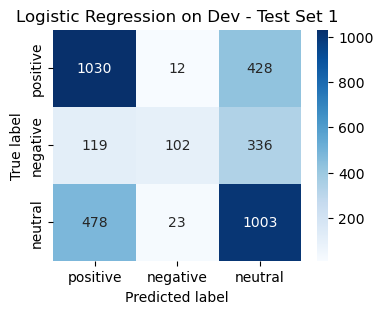


Evaluation for Test Set 2:
Evaluation on Test Set 2:
  Accuracy = 0.6147
  Macro-F1 (all 3 classes) = 0.5146
  Macro-F1 (Positive & Negative only) = 0.4997
  AvgRec = 0.4971


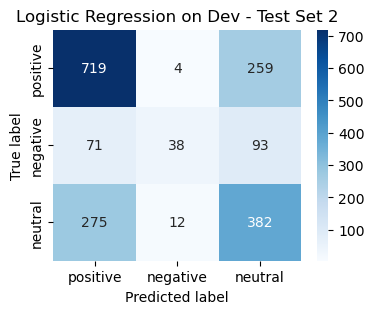


Evaluation for Test Set 3:
Evaluation on Test Set 3:
  Accuracy = 0.6028
  Macro-F1 (all 3 classes) = 0.5254
  Macro-F1 (Positive & Negative only) = 0.4773
  AvgRec = 0.5170


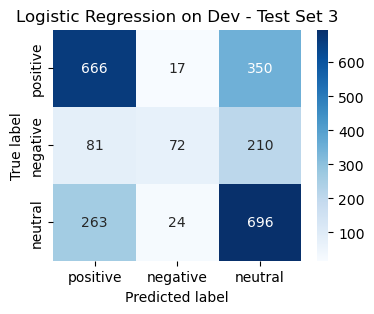

In [103]:
if test_eval:
    evaluate_model(best_nb, X_test_1, y_test_1, dataset_name="Test Set 1", title="Logistic Regression on Dev - Test Set 1")
    evaluate_model(best_nb, X_test_2, y_test_2, dataset_name="Test Set 2", title="Logistic Regression on Dev - Test Set 2")
    evaluate_model(best_nb, X_test_3, y_test_3, dataset_name="Test Set 3", title="Logistic Regression on Dev - Test Set 3")

### SGDClassifier

Fitting 3 folds for each of 324 candidates, totalling 972 fits
Best SGD parameters: {'alpha': 0.0001, 'eta0': 0.01, 'learning_rate': 'constant', 'loss': 'log_loss', 'penalty': 'l2'}
Best cross-val F1 (macro): 0.643461690038038
Evaluation on Val (SGDClassifier):
  Accuracy = 0.6820
  Macro-F1 (all 3 classes) = 0.6735
  Macro-F1 (Positive & Negative only) = 0.6649
  AvgRec = 0.6725


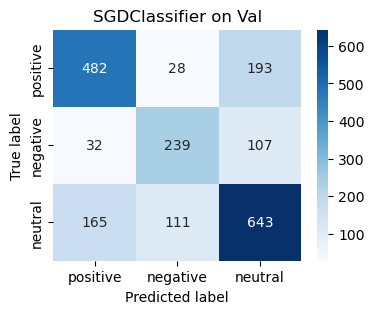

In [104]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Instantiate the SGDClassifier with basic settings.
sgd = SGDClassifier(random_state=42, class_weight='balanced', max_iter=1000, tol=1e-3)

# Expanded parameter grid including eta0.
param_grid_sgd = {
    'loss': ['hinge', 'log_loss'],                   # 'hinge' for SVM-like, 'log_loss' for logistic regression
    'penalty': ['l2', 'l1', 'elasticnet'],            # Regularization types
    'alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1, 10],         # Regularization strength
    'learning_rate': ['optimal', 'constant', 'invscaling'],  # Different learning rate strategies
    'eta0': [0.01, 0.1, 1.0]                          # Initial learning rate (must be > 0)
}

# Use StratifiedKFold to preserve class distributions.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Set up grid search with macro F1 as the scoring metric.
grid_sgd = GridSearchCV(sgd, param_grid_sgd, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
grid_sgd.fit(X_train, y_train)

print("Best SGD parameters:", grid_sgd.best_params_)
print("Best cross-val F1 (macro):", grid_sgd.best_score_)

# Evaluate the best estimator on the validation set.
best_sgd = grid_sgd.best_estimator_
y_val_pred = best_sgd.predict(X_val)

print_metrics(y_val, y_val_pred, dataset_name="Val (SGDClassifier)")
plot_confusion_matrix(y_val, y_val_pred, classes=['positive', 'negative', 'neutral'],
                      title="SGDClassifier on Val")


Evaluation for Test Set 1:
Evaluation on Test Set 1:
  Accuracy = 0.6905
  Macro-F1 (all 3 classes) = 0.6665
  Macro-F1 (Positive & Negative only) = 0.6472
  AvgRec = 0.6505


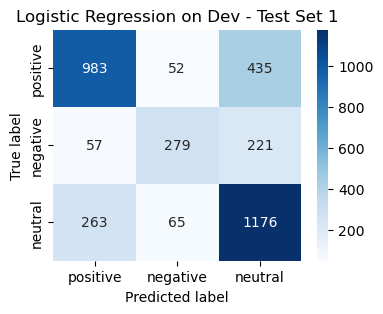


Evaluation for Test Set 2:
Evaluation on Test Set 2:
  Accuracy = 0.6740
  Macro-F1 (all 3 classes) = 0.6495
  Macro-F1 (Positive & Negative only) = 0.6633
  AvgRec = 0.6389


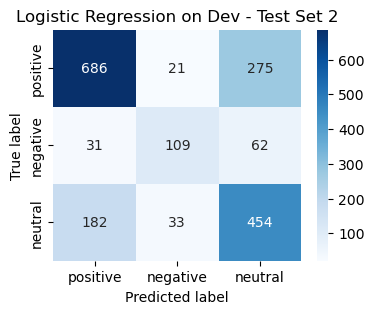


Evaluation for Test Set 3:
Evaluation on Test Set 3:
  Accuracy = 0.6503
  Macro-F1 (all 3 classes) = 0.6248
  Macro-F1 (Positive & Negative only) = 0.6026
  AvgRec = 0.6198


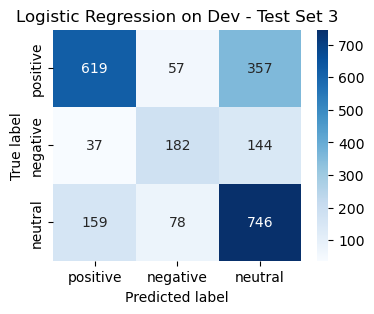

In [105]:
if test_eval:
    evaluate_model(best_sgd, X_test_1, y_test_1, dataset_name="Test Set 1", title="Logistic Regression on Dev - Test Set 1")
    evaluate_model(best_sgd, X_test_2, y_test_2, dataset_name="Test Set 2", title="Logistic Regression on Dev - Test Set 2")
    evaluate_model(best_sgd, X_test_3, y_test_3, dataset_name="Test Set 3", title="Logistic Regression on Dev - Test Set 3")

### LinearSVC

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best LinearSVC parameters: {'C': 0.1, 'dual': False, 'loss': 'squared_hinge', 'penalty': 'l1'}
Best cross-val F1 (macro): 0.6437167109552319
Evaluation on Dev (LinearSVC):
  Accuracy = 0.6835
  Macro-F1 (all 3 classes) = 0.6750
  Macro-F1 (Positive & Negative only) = 0.6651
  AvgRec = 0.6765


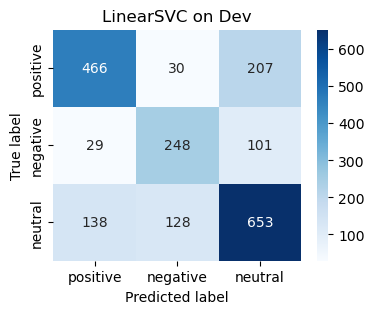

In [106]:
from sklearn.svm import LinearSVC

lin_svc = LinearSVC(class_weight='balanced', max_iter=500)  # allow more iterations for convergence

param_grid_linear = [
    {
        'penalty': ['l2'],
        'loss': ['hinge'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'dual': [True]  # only valid option for hinge with l2
    },
    {
        'penalty': ['l2'],
        'loss': ['squared_hinge'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'dual': [True, False]  # both are valid for squared_hinge
    },
    {
        'penalty': ['l1'],
        'loss': ['squared_hinge'],  # only option for l1
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'dual': [False]  # dual must be False for l1 penalty
    }
]

grid_linear = GridSearchCV(lin_svc, param_grid_linear, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
grid_linear.fit(X_train, y_train)

print("Best LinearSVC parameters:", grid_linear.best_params_)
print("Best cross-val F1 (macro):", grid_linear.best_score_)

best_linear_svc = grid_linear.best_estimator_
y_dev_pred_linear = best_linear_svc.predict(X_val)
print_metrics(y_val, y_dev_pred_linear, dataset_name="Dev (LinearSVC)")
plot_confusion_matrix(y_val, y_dev_pred_linear, title="LinearSVC on Dev")


Evaluation for Test Set 1:
Evaluation on Test Set 1:
  Accuracy = 0.6978
  Macro-F1 (all 3 classes) = 0.6739
  Macro-F1 (Positive & Negative only) = 0.6526
  AvgRec = 0.6598


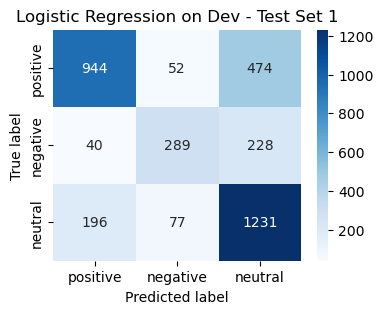


Evaluation for Test Set 2:
Evaluation on Test Set 2:
  Accuracy = 0.6821
  Macro-F1 (all 3 classes) = 0.6601
  Macro-F1 (Positive & Negative only) = 0.6654
  AvgRec = 0.6566


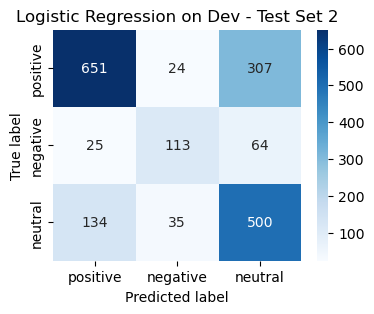


Evaluation for Test Set 3:
Evaluation on Test Set 3:
  Accuracy = 0.6444
  Macro-F1 (all 3 classes) = 0.6224
  Macro-F1 (Positive & Negative only) = 0.5968
  AvgRec = 0.6230


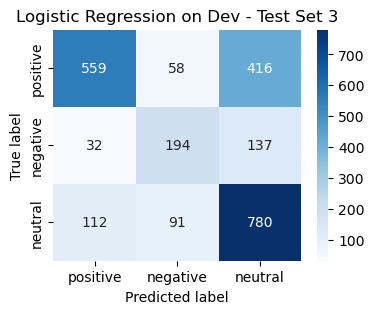

In [107]:
if test_eval:
    evaluate_model(best_linear_svc, X_test_1, y_test_1, dataset_name="Test Set 1", title="Logistic Regression on Dev - Test Set 1")
    evaluate_model(best_linear_svc, X_test_2, y_test_2, dataset_name="Test Set 2", title="Logistic Regression on Dev - Test Set 2")
    evaluate_model(best_linear_svc, X_test_3, y_test_3, dataset_name="Test Set 3", title="Logistic Regression on Dev - Test Set 3")

## LSTM

In [23]:
import numpy as np
import torch
from collections import Counter
import pandas as pd

def build_vocab(texts, max_vocab_size=5000):
    """
    Build a vocabulary dictionary from a list of cleaned text strings.
    Reserve index 0 for <PAD> and index 1 for <UNK>.
    """
    counter = Counter()
    for text in texts:
        tokens = text.split()  # assuming text is already cleaned
        counter.update(tokens)
    most_common = counter.most_common(max_vocab_size - 2)
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for idx, (word, freq) in enumerate(most_common, start=2):
        vocab[word] = idx
    return vocab

# Build vocabulary from the training text.
vocab = build_vocab(train["text"].tolist(), max_vocab_size=5000)
vocab_size = len(vocab)
print("Vocabulary size:", vocab_size)

def load_glove_embeddings(glove_file_path, vocab, embedding_dim=100):
    """
    Load pre-trained GloVe embeddings from a file.
    Returns an embedding matrix of shape (vocab_size, embedding_dim) as a torch.FloatTensor.
    """
    # Initialize embedding matrix with random values.
    embeddings = np.random.uniform(-0.25, 0.25, (len(vocab), embedding_dim))
    # Set the embedding for <PAD> (index 0) to zeros.
    embeddings[0] = np.zeros(embedding_dim)
    
    with open(glove_file_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.strip().split()
            word = values[0]
            if word in vocab:
                vector = np.asarray(values[1:], dtype='float32')
                embeddings[vocab[word]] = vector
    return torch.FloatTensor(embeddings)

# Path to the GloVe file in the "embeddings" folder.
glove_file = "embeddings/glove.6B.100d.txt"
embedding_dim = 100
embedding_matrix = load_glove_embeddings(glove_file, vocab, embedding_dim=embedding_dim)
print("Embedding matrix shape:", embedding_matrix.shape)

Vocabulary size: 5000
Embedding matrix shape: torch.Size([5000, 100])


In [24]:
# Calculate and set max_length according to 95th percentile of training set
token_lengths = train["text"].apply(lambda x: len(x.split()))
max_length = int(np.percentile(token_lengths, 95))

def text_to_sequence(text, vocab, max_length):
    """
    Convert cleaned text into a sequence of token indices.
    Pads or truncates to max_length.
    """
    tokens = text.split()  # assume text is already cleaned
    seq = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    if len(seq) < max_length:
        seq = seq + [vocab["<PAD>"]] * (max_length - len(seq))
    else:
        seq = seq[:max_length]
    return seq

# Convert training and validation texts to sequences.
train_sequences = [text_to_sequence(text, vocab, max_length) for text in train["text"]]
val_sequences   = [text_to_sequence(text, vocab, max_length) for text in val["text"]]

# Convert to PyTorch LongTensors.
X_train_tensor = torch.LongTensor(train_sequences)
X_val_tensor   = torch.LongTensor(val_sequences)

# map sentiment labels to numeric values so it can be turned into a tensor
sentiment_map = {'positive': 0, 'negative': 1, 'neutral': 2}
train["sentiment"] = train["sentiment"].map(sentiment_map)
val["sentiment"] = val["sentiment"].map(sentiment_map)

# Assume sentiment labels are already numeric (e.g., 0, 1, 2).
y_train_tensor = torch.LongTensor(train["sentiment"].values)
y_val_tensor   = torch.LongTensor(val["sentiment"].values)

In [25]:
# import torch
# import torch.nn as nn
# import torch.nn.functional as F

# class LSTMTransformerSentiment(nn.Module):
#     def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers,
#                  bidirectional, dropout, embedding_matrix, pad_idx, nhead=4, transformer_layers=1):
#         super(LSTMTransformerSentiment, self).__init__()
        
#         # 1. Embedding Layer (initialized with pre-trained embeddings and frozen)
#         self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
#         self.embedding.weight.data.copy_(embedding_matrix)
#         self.embedding.weight.requires_grad = False  # Freeze embeddings
        
#         # 2. Stacked LSTM Layers (can be bidirectional)
#         self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers, 
#                             bidirectional=bidirectional, batch_first=True,
#                             dropout=dropout if n_layers > 1 else 0)
#         lstm_out_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
#         # 3. Transformer Encoder Block (BERT-like component)
#         # This block applies multi-head self-attention and a feed-forward network
#         encoder_layer = nn.TransformerEncoderLayer(d_model=lstm_out_dim, nhead=nhead, dropout=dropout, batch_first=True)
#         self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=transformer_layers)
        
#         # 4. Final Classification Head
#         # We'll use mean pooling over the sequence dimension after the transformer.
#         self.fc = nn.Linear(lstm_out_dim, output_dim)
    
#     def forward(self, text):
#         # text: [batch_size, max_length]
        
#         # Embedding lookup (returns [batch_size, max_length, embedding_dim])
#         embedded = self.embedding(text)
        
#         # Process embeddings with LSTM
#         lstm_out, (hidden, cell) = self.lstm(embedded)  # lstm_out: [batch_size, max_length, lstm_out_dim]
        
#         # Pass LSTM outputs through the Transformer Encoder block
#         # (batch_first=True is set, so input shape remains [batch_size, seq_len, d_model])
#         transformer_out = self.transformer_encoder(lstm_out)
        
#         # Pool over the time dimension (e.g., average pooling)
#         pooled = torch.mean(transformer_out, dim=1)  # [batch_size, lstm_out_dim]
        
#         # Pass the pooled representation through the classifier
#         output = self.fc(pooled)  # [batch_size, output_dim]
#         return output

# # --- Hyperparameters ---
# vocab_size = len(vocab)       # Should be ≤ 5000 as per your spec.
# embedding_dim = 100           # As specified (using GloVe 100d)
# hidden_dim = 256              # Hidden state size for LSTM
# output_dim = 3                # Three sentiment classes: positive, negative, neutral
# n_layers = 2                  # Two stacked LSTM layers
# bidirectional = True          # Use bidirectional LSTM
# dropout = 0.5                 # Dropout rate for LSTM and transformer
# pad_idx = vocab["<PAD>"]      # Padding index from your vocabulary
# nhead = 4                     # Number of attention heads in Transformer block
# transformer_layers = 1        # Number of Transformer encoder layers
# batch_size = 128

# # Instantiate the model
# model = LSTMTransformerSentiment(
#     vocab_size=vocab_size,
#     embedding_dim=embedding_dim,
#     hidden_dim=hidden_dim,
#     output_dim=output_dim,
#     n_layers=n_layers,
#     bidirectional=bidirectional,
#     dropout=dropout,
#     embedding_matrix=embedding_matrix,
#     pad_idx=pad_idx,
#     nhead=nhead,
#     transformer_layers=transformer_layers
# )

# print(model)

# def count_parameters(model):
#     return sum(p.numel() for p in model.parameters() if p.requires_grad)

# print(f'The model has {count_parameters(model):,} trainable parameters.')

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LSTMWithAttention(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers,
                 bidirectional, dropout, embedding_matrix, pad_idx):
        super(LSTMWithAttention, self).__init__()
        # 1. Embedding Layer: Initialize with pre-trained embeddings and freeze them.
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.embedding.weight.data.copy_(embedding_matrix)
        self.embedding.weight.requires_grad = False
        
        # 2. Stacked LSTM Layers.
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers,
                            bidirectional=bidirectional, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0)
        lstm_out_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
        # 3. Attention Mechanism.
        # We'll project LSTM outputs to a hidden space, then compute scalar scores.
        self.attn_fc = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_vector = nn.Linear(lstm_out_dim, 1, bias=False)
        
        # 4. Final Classification Layer with Dropout.
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(lstm_out_dim, output_dim)
    
    def forward(self, text):
        # text: [batch_size, max_length]
        embedded = self.embedding(text)  # [batch_size, max_length, embedding_dim]
        lstm_out, _ = self.lstm(embedded)  # lstm_out: [batch_size, max_length, lstm_out_dim]
        
        # Apply attention:
        # Compute energy scores from LSTM outputs.
        energy = torch.tanh(self.attn_fc(lstm_out))  # [batch_size, max_length, lstm_out_dim]
        # Project to a single scalar per time step.
        attn_scores = self.attn_vector(energy)       # [batch_size, max_length, 1]
        # Softmax over the time dimension.
        attn_weights = F.softmax(attn_scores, dim=1)  # [batch_size, max_length, 1]
        # Compute the context vector as the weighted sum of LSTM outputs.
        context = torch.sum(lstm_out * attn_weights, dim=1)  # [batch_size, lstm_out_dim]
        
        context = self.dropout(context)
        output = self.fc(context)  # [batch_size, output_dim]
        return output

# --- Hyperparameters ---
vocab_size = len(vocab)       # e.g. ≤ 5000, as defined from your training data.
embedding_dim = 100           # Using GloVe 100d
hidden_dim = 256              # Hidden state size
output_dim = 3                # Three sentiment classes: positive, negative, neutral
n_layers = 2                  # Two stacked LSTM layers
bidirectional = True          # Use bidirectional LSTM
dropout = 0.5                 # Dropout rate for LSTM and attention
pad_idx = vocab["<PAD>"]      # Padding index from your vocabulary
batch_size = 64

# Instantiate the LSTM + Attention model.
model = LSTMWithAttention(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    output_dim=output_dim,
    n_layers=n_layers,
    bidirectional=bidirectional,
    dropout=dropout,
    embedding_matrix=embedding_matrix,
    pad_idx=pad_idx
)

print(model)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(model):,} trainable parameters.')


LSTMWithAttention(
  (embedding): Embedding(5000, 100, padding_idx=0)
  (lstm): LSTM(100, 256, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (attn_fc): Linear(in_features=512, out_features=512, bias=True)
  (attn_vector): Linear(in_features=512, out_features=1, bias=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=3, bias=True)
)
The model has 2,574,851 trainable parameters.


In [27]:
torch.cuda.empty_cache()

Epochs:   1%|          | 1/100 [00:05<08:39,  5.25s/it]

Epoch 1: Train Loss = 0.9239, Val Loss = 0.8518
Overall Macro F1 = 0.5542, Macro F1 (Pos & Neg) = 0.5735


Epochs:   2%|▏         | 2/100 [00:09<08:00,  4.90s/it]

Epoch 2: Train Loss = 0.8531, Val Loss = 0.8220
Overall Macro F1 = 0.5830, Macro F1 (Pos & Neg) = 0.5995


Epochs:   3%|▎         | 3/100 [00:14<07:43,  4.78s/it]

...

Epoch 10: Train Loss = 0.7607, Val Loss = 0.7555
Overall Macro F1 = 0.6289, Macro F1 (Pos & Neg) = 0.6437
1 epochs without improvement


Epochs:  11%|█         | 11/100 [00:52<06:56,  4.68s/it]

Epoch 11: Train Loss = 0.7514, Val Loss = 0.7507
Overall Macro F1 = 0.6289, Macro F1 (Pos & Neg) = 0.6445
2 epochs without improvement


Epochs:  11%|█         | 11/100 [00:56<07:40,  5.17s/it]


Epoch 12: Train Loss = 0.7429, Val Loss = 0.7502
Overall Macro F1 = 0.6276, Macro F1 (Pos & Neg) = 0.6419
3 epochs without improvement
Early stopping triggered. No improvement for 3 epochs.


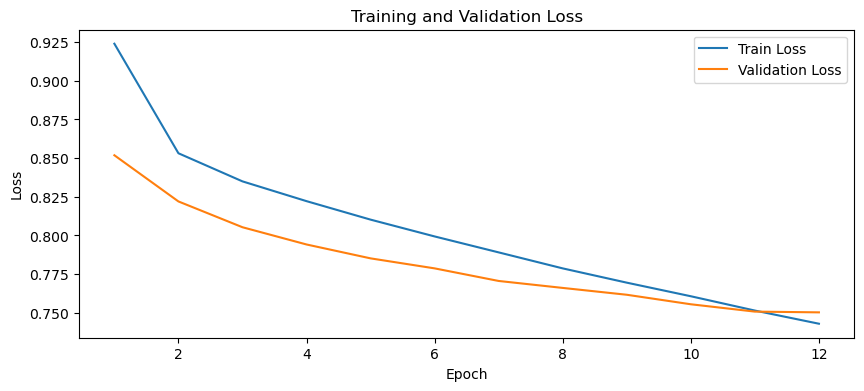

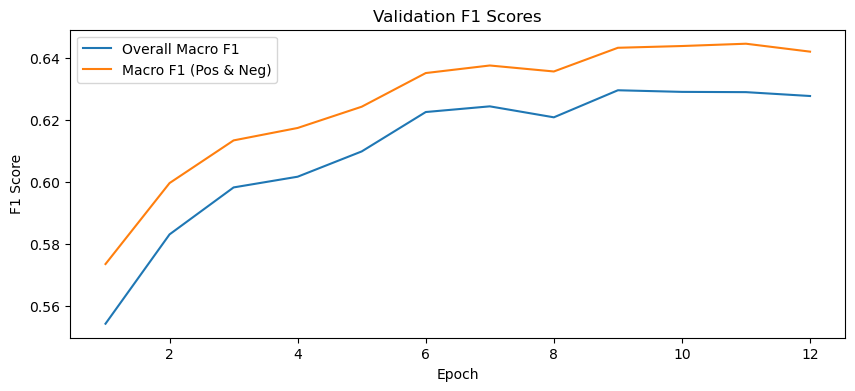

FINAL Validation Results:
  Loss: 0.7502
  Overall Macro F1: 0.6276
  Macro F1 (Positive & Negative): 0.6419
Evaluation on Validation:
  Accuracy = 0.6285
  Macro-F1 (all 3 classes) = 0.6276
  Macro-F1 (Positive & Negative only) = 0.6419
  AvgRec = 0.6547


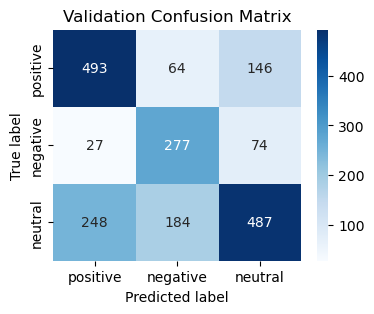

In [28]:
import torch.optim as optim
from tqdm import tqdm
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Helper to compute macro F1 for positive & negative classes.
def macro_f1_pos_neg(y_true, y_pred):
    # Assumes positive=0 and negative=1.
    return f1_score(y_true, y_pred, labels=[0, 1], average='macro')

# Updated confusion matrix plotting function that accepts numeric labels.
def plot_confusion_matrix_updated(y_true, y_pred, classes, class_names, title="Confusion Matrix"):
    """
    Plots a confusion matrix.
    y_true and y_pred are numeric arrays.
    'classes' is a list of numeric labels (e.g., [0, 1, 2]),
    'class_names' are the corresponding display names (e.g., ['positive', 'negative', 'neutral']).
    """
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)
X_val_tensor   = X_val_tensor.to(device)
y_val_tensor   = y_val_tensor.to(device)

# -------------------------
# Assuming y_train is a list/array of class labels (0 = positive, 1 = negative, 2 = neutral)
class_counts = Counter(y_train)
count_dict = dict(class_counts)
total = sum(count_dict.values())

# Order: positive (0), negative (1), neutral (2)
weights = [total / count_dict[i] for i in ["positive", "negative", "neutral"]]
weights = torch.FloatTensor(weights).to(device)
# -------------------------
optimizer = optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss(weight=weights)

def train_epoch(model, X, y, optimizer, criterion, batch_size=batch_size):
    model.train()
    epoch_loss = 0
    num_batches = (len(X) + batch_size - 1) // batch_size
    pbar = tqdm(range(0, len(X), batch_size), desc="Training Batches", total=num_batches, leave=False)
    for i in pbar:
        x_batch = X[i:i+batch_size]
        y_batch = y[i:i+batch_size]
        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()
        batch_loss = loss.item() * x_batch.size(0)
        epoch_loss += batch_loss
        current_avg_loss = epoch_loss / (i + x_batch.size(0))
        pbar.set_postfix({"AvgLoss": f"{current_avg_loss:.4f}"})
    return epoch_loss / len(X)

def evaluate(model, X, y, criterion, batch_size=batch_size):
    model.eval()
    epoch_loss = 0
    all_preds = []
    num_batches = (len(X) + batch_size - 1) // batch_size
    pbar = tqdm(range(0, len(X), batch_size), desc="Evaluation Batches", total=num_batches, leave=False)
    for i in pbar:
        x_batch = X[i:i+batch_size]
        y_batch = y[i:i+batch_size]
        with torch.no_grad():
            predictions = model(x_batch)
            loss = criterion(predictions, y_batch)
            batch_loss = loss.item() * x_batch.size(0)
            epoch_loss += batch_loss
            all_preds.append(predictions.argmax(dim=1).cpu().numpy())
            current_avg_loss = epoch_loss / (i + x_batch.size(0))
            pbar.set_postfix({"AvgLoss": f"{current_avg_loss:.4f}"})
    return epoch_loss / len(X), np.concatenate(all_preds)

# Early stopping parameters
patience = 3
best_val_f1 = 0.0
epochs_without_improvement = 0

# Lists to store metrics for convergence plotting
train_losses = []
val_losses = []
overall_f1_scores = []
pos_neg_f1_scores = []

num_epochs = 100  # high number; early stopping will break out if no improvement
for epoch in tqdm(range(num_epochs), desc="Epochs"):
    train_loss = train_epoch(model, X_train_tensor, y_train_tensor, optimizer, criterion, batch_size=batch_size)
    val_loss, val_preds = evaluate(model, X_val_tensor, y_val_tensor, criterion, batch_size=batch_size)
    
    # Convert ground truth to numpy for metric computation.
    y_val_np = y_val_tensor.cpu().numpy()
    overall_macro_f1 = f1_score(y_val_np, val_preds, average='macro')
    pos_neg_macro_f1 = macro_f1_pos_neg(y_val_np, val_preds)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    overall_f1_scores.append(overall_macro_f1)
    pos_neg_f1_scores.append(pos_neg_macro_f1)
    
    tqdm.write(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f}, Val Loss = {val_loss:.4f}")
    tqdm.write(f"Overall Macro F1 = {overall_macro_f1:.4f}, Macro F1 (Pos & Neg) = {pos_neg_macro_f1:.4f}")
    
    # Early stopping based on overall macro F1
    if overall_macro_f1 > best_val_f1:
        best_val_f1 = overall_macro_f1
        epochs_without_improvement = 0
        best_model_state = model.state_dict()  # save best model state
    else:
        epochs_without_improvement += 1
        tqdm.write(f"{epochs_without_improvement} epochs without improvement")
        if epochs_without_improvement >= patience:
            tqdm.write(f"Early stopping triggered. No improvement for {patience} epochs.")
            break

# Plot convergence curves for loss and F1 scores
epochs_range = range(1, len(train_losses) + 1)
plt.figure(figsize=(10, 4))
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(epochs_range, overall_f1_scores, label="Overall Macro F1")
plt.plot(epochs_range, pos_neg_f1_scores, label="Macro F1 (Pos & Neg)")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Validation F1 Scores")
plt.legend()
plt.show()

# --- Final Evaluation on Validation Data ---
model.load_state_dict(best_model_state)
model.eval()
final_val_loss, final_val_preds = evaluate(model, X_val_tensor, y_val_tensor, criterion, batch_size=batch_size)
y_val_np = y_val_tensor.cpu().numpy()
final_overall_f1 = f1_score(y_val_np, final_val_preds, average='macro')
final_pos_neg_f1 = macro_f1_pos_neg(y_val_np, final_val_preds)

print("FINAL Validation Results:")
print(f"  Loss: {final_val_loss:.4f}")
print(f"  Overall Macro F1: {final_overall_f1:.4f}")
print(f"  Macro F1 (Positive & Negative): {final_pos_neg_f1:.4f}")

print_metrics(y_val_np, final_val_preds, dataset_name="Validation")
plot_confusion_matrix_updated = plot_confusion_matrix_updated  # Using our updated function
plot_confusion_matrix_updated(y_val_np, final_val_preds, classes=[0, 1, 2],
                              class_names=['positive', 'negative', 'neutral'],
                              title="Validation Confusion Matrix")


--- Evaluating Test Set 1 ---


Test Set 1 Loss: 0.7815
Test Set 1 Overall Macro F1: 0.6488
Test Set 1 Macro F1 (Positive & Negative): 0.6392
Evaluation on Test Set 1:
  Accuracy = 0.6667
  Macro-F1 (all 3 classes) = 0.6488
  Macro-F1 (Positive & Negative only) = 0.6392
  AvgRec = 0.6529


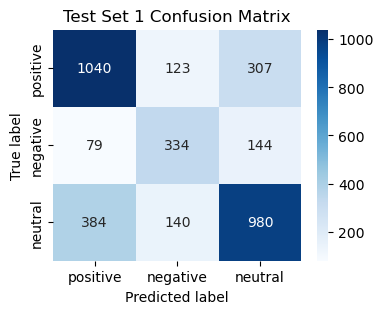


--- Evaluating Test Set 2 ---


Test Set 2 Loss: 0.7489
Test Set 2 Overall Macro F1: 0.6140
Test Set 2 Macro F1 (Positive & Negative): 0.6288
Evaluation on Test Set 2:
  Accuracy = 0.6519
  Macro-F1 (all 3 classes) = 0.6140
  Macro-F1 (Positive & Negative only) = 0.6288
  AvgRec = 0.6155


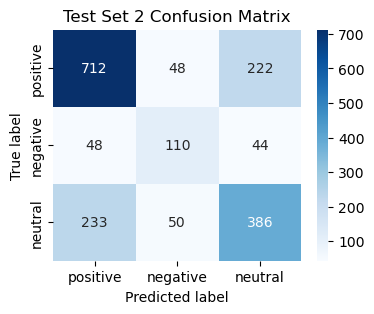


--- Evaluating Test Set 3 ---


Test Set 3 Loss: 0.8228
Test Set 3 Overall Macro F1: 0.5900
Test Set 3 Macro F1 (Positive & Negative): 0.5859
Evaluation on Test Set 3:
  Accuracy = 0.6082
  Macro-F1 (all 3 classes) = 0.5900
  Macro-F1 (Positive & Negative only) = 0.5859
  AvgRec = 0.6125


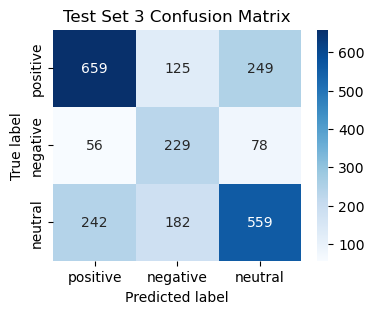

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Updated confusion matrix plotting function:
def plot_confusion_matrix(y_true, y_pred, classes, class_names, title="Confusion Matrix"):
    """
    Plots a confusion matrix.
    y_true and y_pred should be numeric.
    'classes' is a list of numeric labels (e.g., [0, 1, 2]).
    'class_names' are the corresponding display names (e.g., ['positive', 'negative', 'neutral']).
    """
    
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

# --- Load the best model state and set model to evaluation mode ---
model.load_state_dict(best_model_state)
model.eval()

# Define a dictionary mapping test set names to their DataFrames.
test_sets = {
    "Test Set 1": test_1,
    "Test Set 2": test_2,
    "Test Set 3": test_3,
}

# Define sentiment mapping to convert string labels to numeric values.
sentiment_map = {'positive': 0, 'negative': 1, 'neutral': 2}

# Loop over each test set.
for set_name, df in test_sets.items():
    print(f"\n--- Evaluating {set_name} ---")
    
    # Map sentiment labels to numeric values.
    df["sentiment"] = df["sentiment"].map(sentiment_map)
    
    # Convert texts to sequences using your text_to_sequence() function.
    sequences = [text_to_sequence(text, vocab, max_length) for text in df["text"].tolist()]
    
    # Convert sequences to a PyTorch LongTensor.
    X_tensor = torch.LongTensor(sequences).to(device)
    y_tensor = torch.LongTensor(df["sentiment"].values).to(device)
    
    # Evaluate on the test set.
    test_loss, test_preds = evaluate(model, X_tensor, y_tensor, criterion, batch_size=batch_size)
    
    # Convert ground truth labels to numpy for metric computation.
    y_np = y_tensor.cpu().numpy()
    
    # Compute overall macro F1 and macro F1 for positive & negative classes.
    overall_f1 = f1_score(y_np, test_preds, average='macro')
    pos_neg_f1 = macro_f1_pos_neg(y_np, test_preds)
    
    print(f"{set_name} Loss: {test_loss:.4f}")
    print(f"{set_name} Overall Macro F1: {overall_f1:.4f}")
    print(f"{set_name} Macro F1 (Positive & Negative): {pos_neg_f1:.4f}")
    
    # Print detailed metrics using your helper function.
    print_metrics(y_np, test_preds, dataset_name=set_name)
    
    # Plot the confusion matrix.
    plot_confusion_matrix(y_np, test_preds, classes=[0,1,2],
                          class_names=['positive', 'negative', 'neutral'],
                          title=f"{set_name} Confusion Matrix")

In [ ]:
def read_test(testset):
    '''
    readin the testset and return a dictionary
    :param testset: str, the file name of the testset to compare
    '''
    id_gts = {}
    with open(testset, 'r', encoding='utf8') as fh:
        for line in fh:
            fields = line.split('\t')
            tweetid = fields[0]
            gt = fields[1]

            id_gts[tweetid] = gt

    return id_gts

test_1_ids = read_test("twitter-test1.txt")
test_2_ids = read_test("twitter-test1.txt")
test_3_ids = read_test("twitter-test1.txt")

{'163361196206957578': 'neutral',
 '768006053969268950': 'negative',
 '742616104384772304': 'neutral',
 '102313285628711403': 'neutral',
 '653274888624828198': 'neutral',
 '420747042670198316': 'negative',
 '865097686752334952': 'positive',
 '822064800445716046': 'neutral',
 '055480020953212084': 'neutral',
 '170392754891582126': 'neutral',
 '429443270273347255': 'neutral',
 '677748222480342835': 'positive',
 '051532680339634183': 'negative',
 '220323262844863802': 'neutral',
 '010626432232448553': 'neutral',
 '128650893668172764': 'positive',
 '522172623221870367': 'positive',
 '406316086760621579': 'neutral',
 '266953303729385574': 'positive',
 '442261589864246821': 'positive',
 '267372990522222442': 'negative',
 '700412481961851264': 'positive',
 '855625354261036450': 'positive',
 '578446202147364926': 'neutral',
 '729439526827995507': 'neutral',
 '810763059461202071': 'neutral',
 '885726184364930528': 'positive',
 '263123496026519597': 'neutral',
 '960689731242555262': 'negative',


In [ ]:
def get_eval(df, model):
    "make predictions on a dataset and return a dictionary"
    preds_dict = {}

    for row in df.iterrows():
        tweet_id = df["tweet_id"]
        text - df["text"]
        sent = model.predict(text)
        preds_dict[tweet_id] = sent
    
    return preds_dict

